# Atividade 7 — Meios de transporte por cor ou raça


## Parte 1 — Brasil e gráficos de pizza

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
arquivo = Path('Tabela_13_Meio_de_transporte.xlsx')
if not arquivo.exists():
    raise FileNotFoundError(f'Coloque {arquivo.name} na mesma pasta do notebook.')

In [2]:
df_brasil = pd.read_excel(arquivo, sheet_name='Exemplo gráfico Brasil', header=1)
df_brasil

,Meio de transporte/cor ou raça,Branca,Preta ou parda,Indígena
0,A pé,19.4,24.8,37.5
1,Bicicleta,3.2,5.2,5.9
2,Motocicleta ou Mototaxi,9.9,14.2,15.4
3,"Automóvel, taxi ou assemelhados",41.8,20.6,15.2
4,Transporte coletivo,25.2,34.6,22.4
5,Outros,0.5,0.6,3.6


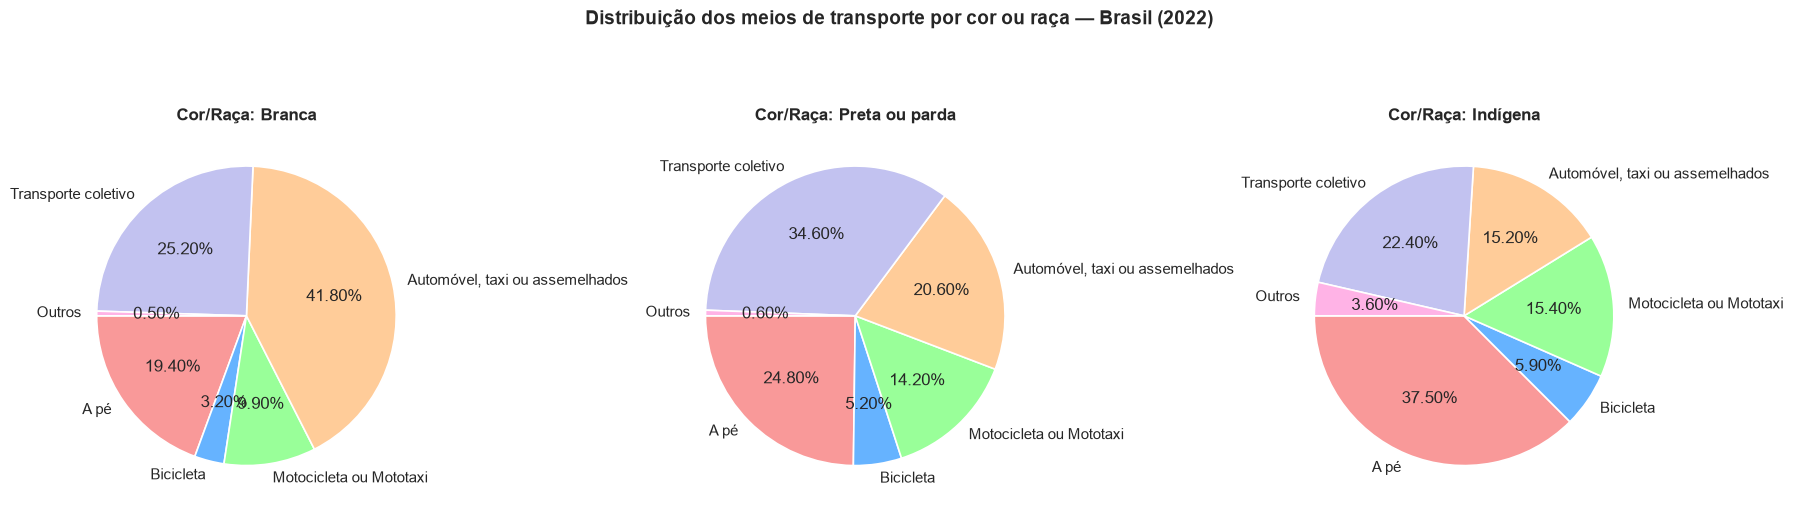

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
cores = ['#f99999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0', '#ffb3e6']
grupos = ['Branca', 'Preta ou parda', 'Indígena']

for i, col in enumerate(grupos):
    axes[i].pie(
        df_brasil[col],
        labels=df_brasil['Meio de transporte/cor ou raça'],
        autopct='%1.2f%%',
        startangle=180,
        colors=cores,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.2}
    )
    axes[i].set_title(f'Cor/Raça: {col}', fontsize=12, fontweight='bold')

plt.suptitle('Distribuição dos meios de transporte por cor ou raça — Brasil (2022)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('grafico_transporte.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
comparacao = df_brasil.set_index('Meio de transporte/cor ou raça')[grupos]
comparacao['Diferença (p.p.)'] = comparacao.max(axis=1) - comparacao.min(axis=1)
comparacao.round(1)

,Branca,Preta ou parda,Indígena,Diferença (p.p.)
Meio de transporte/cor ou raça,,,,
A pé,19.4,24.8,37.5,18.1
Bicicleta,3.2,5.2,5.9,2.7
Motocicleta ou Mototaxi,9.9,14.2,15.4,5.5
"Automóvel, taxi ou assemelhados",41.8,20.6,15.2,26.6
Transporte coletivo,25.2,34.6,22.4,12.2
Outros,0.5,0.6,3.6,3.1


## Parte 2 — Estados e municípios com `melt` e `groupby`

In [5]:
df = pd.read_excel(arquivo, sheet_name='BR GR UF MU', header=[1, 2])
df.columns = ['Local'] + [f'{raca}|{meio}' for raca, meio in df.columns[1:]]
df.head()

,Local,Branca|A pé,Branca|Bicicleta,Branca|Motocicleta ou Mototaxi,"Branca|Automóvel, taxi ou assemelhados",Branca|Transporte coletivo,Branca|Outros,Preta ou Parda|A pé,Preta ou Parda|Bicicleta,Preta ou Parda|Motocicleta ou Mototaxi,"Preta ou Parda|Automóvel, taxi ou assemelhados",Preta ou Parda|Transporte coletivo,Preta ou Parda|Outros,Indígena|A pé,Indígena|Bicicleta,Indígena|Motocicleta ou Mototaxi,"Indígena|Automóvel, taxi ou assemelhados",Indígena|Transporte coletivo,Indígena|Outros
0,Brasil,19.4,3.2,9.9,41.8,25.2,0.5,24.8,5.2,14.2,20.6,34.6,0.6,37.5,5.9,15.4,15.2,22.4,3.6
1,Norte,15.2,5.9,24.5,35.1,17.9,1.3,21.3,8.6,27.7,19.5,20.8,2.1,46.8,4.8,19.2,9.5,9.1,10.6
2,Nordeste,24.9,2.6,19.9,31.6,20.5,0.5,31.7,4.1,20.8,16.9,26,0.6,42,4.2,19.4,13.1,20.6,0.7
3,Sudeste,18.5,2.7,7.1,40.4,30.8,0.5,23,4.5,7,19.5,45.5,0.5,26.2,5.6,5.9,22.3,39.4,0.6
4,Sul,20.8,3.5,7.3,48,20,0.5,24,5.5,8.6,29.2,32.2,0.5,31.1,3.1,5.7,22.8,36.4,1


In [6]:
estados = [
    'Rondônia', 'Acre', 'Amazonas', 'Roraima', 'Pará', 'Amapá', 'Tocantins',
    'Maranhão', 'Piauí', 'Ceará', 'Rio Grande do Norte', 'Paraíba', 'Pernambuco',
    'Alagoas', 'Sergipe', 'Bahia', 'Minas Gerais', 'Espírito Santo',
    'Rio de Janeiro', 'São Paulo', 'Paraná', 'Santa Catarina', 'Rio Grande do Sul',
    'Mato Grosso do Sul', 'Mato Grosso', 'Goiás', 'Distrito Federal'
]

# Lista apenas os estados solicitados.
df_estados = df[df['Local'].isin(estados)].copy()
df_estados['Local'].reset_index(drop=True).to_frame('Estado')

,Estado
0,Rondônia
1,Acre
2,Amazonas
3,Roraima
4,Pará
5,Amapá
6,Tocantins
7,Maranhão
8,Piauí
9,Ceará


In [7]:
def para_formato_longo(dados):
    plano = dados.copy()
    longo = plano.melt(id_vars='Local', var_name='Raça_Meio', value_name='Percentual')
    longo[['Raça', 'Meio de transporte']] = longo['Raça_Meio'].str.split('|', n=1, expand=True)
    longo['Percentual'] = pd.to_numeric(longo['Percentual'], errors='coerce')
    return longo.drop(columns='Raça_Meio').dropna(subset=['Percentual'])

longo_estados = para_formato_longo(df_estados)
media_estados = (
    longo_estados.groupby(['Local', 'Meio de transporte'], as_index=False)['Percentual'].mean()
)
media_estados.head()

,Local,Meio de transporte,Percentual
0,Acre,A pé,30.500000
1,Acre,"Automóvel, taxi ou assemelhados",25.166667
2,Acre,Bicicleta,7.933333
3,Acre,Motocicleta ou Mototaxi,24.333333
4,Acre,Outros,2.833333


In [8]:
def extremo(tabela, meio, maior=True):
    recorte = tabela[tabela['Meio de transporte'].eq(meio)]
    indice = recorte['Percentual'].idxmax() if maior else recorte['Percentual'].idxmin()
    return recorte.loc[indice, ['Local', 'Percentual']]

estado_mais_coletivo = extremo(media_estados, 'Transporte coletivo', maior=True)
estado_menos_coletivo = extremo(media_estados, 'Transporte coletivo', maior=False)
display(estado_mais_coletivo.to_frame('Estado com maior uso coletivo'))
display(estado_menos_coletivo.to_frame('Estado com menor uso coletivo'))

,Estado com maior uso coletivo
Local,Rio de Janeiro
Percentual,52.233333


,Estado com menor uso coletivo
Local,Rondônia
Percentual,4.333333


In [9]:
nao_municipios = estados + ['Brasil', 'Norte', 'Nordeste', 'Sudeste', 'Sul', 'Centro-oeste']
df_municipios = df[~df['Local'].isin(nao_municipios)].dropna(subset=['Local']).copy()
longo_municipios = para_formato_longo(df_municipios)
media_municipios = (
    longo_municipios.groupby(['Local', 'Meio de transporte'], as_index=False)['Percentual'].mean()
)

cidade_bicicleta = extremo(media_municipios, 'Bicicleta', maior=True)
cidade_carro = extremo(media_municipios, 'Automóvel, taxi ou assemelhados', maior=True)
display(cidade_bicicleta.to_frame('Cidade com maior uso de bicicleta'))
display(cidade_carro.to_frame('Cidade com maior uso de carro'))

,Cidade com maior uso de bicicleta
Local,Tuiuti (SP)
Percentual,100.0


,Cidade com maior uso de carro
Local,Bom Jesus do Oeste (SC)
Percentual,86.05
